1. Список всех выполняемых процессов переписать в файл Task_1. Создать в каталоге sandbox каталог sandbox-2, переместить туда файлы Task_2, Task_3. Переписать содержимое файла /bin/ls в файл Task_2, переименовав его в "myls", установить права доступа на файл "myls" - "r-xr--r--". Добавить в файл Task_3 информацию о ядре системы.

cd sandbox

ps aux > Task_1

mkdir sandbox-2

mv Task_2 Task_3 sandbox-2/

cp /bin/ls sandbox-2/Task_2

mv sandbox-2/Task_2 sandbox-2/myls

chmod 544 sandbox-2/myls

uname -a >> sandbox-2/Task_3


2. Разработать программу на языке ассемблера, которая принимает в качестве параметра командной строки значение  n , выполняет расчет указанного выражения и выводит результат на экран:
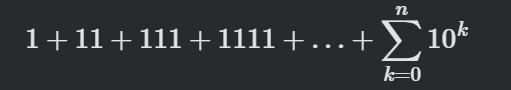

In [ ]:
format elf64
public _start

include 'func.asm'

section '.bss' writable
    buffer rb 64

section '.data' writable
    error db "error occured while reading arguments", 0

section '.text' executable
    _start:
        pop rcx
        cmp rcx, 2
        jl .err

        mov rsi, [rsp+8]
        call str_number
        mov r8, rax
        xor r9, r9
        xor r10, r10
        xor rcx, rcx
        mov rbx, 10

.loop:
    cmp rcx, r8
    ja .done

    mov rax, r10
    mul rbx
    inc rax
    mov r10, rax
    add r9, r10
    inc rcx
    jmp .loop

.done:
    mov rax, r9
    mov rsi, buffer
    call number_str
    call print_str
    call new_line
    call exit

.err:
    mov rsi, error
    call print_str
    call exit


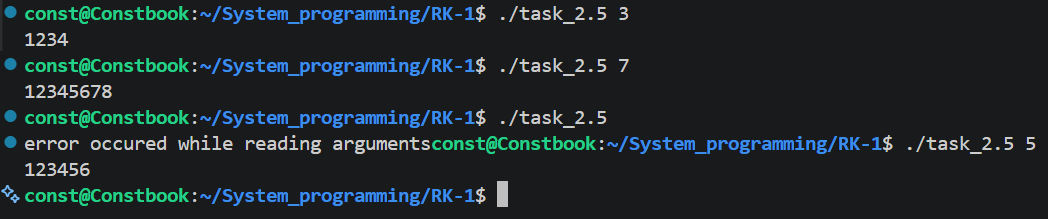

3. Написать программу на языке ассемблера, которая принимает один параметр командной строки - имя некоторого каталога. Программа выбирает несколько случайных файлов в каталоге и меняет их названия на случайные.

In [ ]:
format elf64
public _start

include 'func.asm'

section '.data' writable
    rnd   db "/dev/random", 0
    error db "error occured while reading arguments", 0x0a, 0

section '.bss' writable
    buffer rb 100000 ; сюда читаем содержимое каталога
    old rb 4096
    new rb 4096
    number rq 1 ; сюда читаем случайный байт

section '.text' executable
    _start:
        pop rcx
        cmp rcx, 2
        jne .err

        mov rax, 2
        mov rdi, rnd
        mov rsi, 0o
        syscall
        cmp rax, 0
        jl .err
        mov r12, rax ; r12 = дескриптор /dev/random

        mov rax, 2
        mov rdi, [rsp+8]
        mov rsi, 65536 ; флаги O_RDONLY | O_DIRECTORY
        syscall
        cmp rax, 0
        jl .err
        mov r8, rax ; r8 = дескриптор каталога

        mov rax, 78 ; системный вызов getdents
        mov rdi, r8
        mov rsi, buffer
        mov rdx, 100000
        syscall
        mov r10, rax ; r10 = сколько байт прочитали

        ;закрываем каталог
        mov rax, 3
        mov rdi, r8
        syscall

        cmp r10, 0
        jle .end

        mov rsi, [rsp+8]
        mov rdi, old
        call copy_str ; возвращает в rdi адрес заверщающего нуля
        mov byte [rdi], '/' ; "каталог/старое_имя"
        inc rdi
        mov r13, rdi ; r13 = место для имени файла в old

        mov rsi, [rsp+8]
        mov rdi, new
        call copy_str
        mov byte [rdi], '/' ; "каталог/новое_имя"
        inc rdi
        mov r14, rdi ; r14 = место для имени файла в new

        xor r15, r15 ; r15 = текущая позиция в buffer

.loop:
    cmp r15, r10
    jge .end

    xor r9, r9
    mov r9w, word [buffer+16+r15] ; d_reclen - размер всей структуры linux_dirent

    mov al, byte [buffer+r9-1+r15]
    cmp al, 8
    jne .next ; пропускаем все файлы кроме обычных

    call random_byte
    and rax, 1 ;файл выбирается, если случайный байт нечётный
    cmp rax, 0
    je .next

    mov rsi, buffer
    add rsi, 18
    add rsi, r15 ; добавляем старое имя файла в путь (начинается со смещения 18)
    mov rdi, r13
    call copy_str

    mov rdi, r14
    mov rbx, 12 ; имя файла из 12 случайных букв

.gen:
    call random_byte
    xor rdx, rdx
    mov rcx, 26
    div rcx ; rdx = случайное число от 0 до 25
    add dl, 'a'
    mov byte [rdi], dl
    inc rdi
    dec rbx
    cmp rbx, 0
    jne .gen
    mov byte [rdi], 0

    mov rax, 82 ;системный вызов rename
    mov rdi, old
    mov rsi, new
    syscall
    cmp rax, 0
    jl .next

.next:
    add r15, r9 ; переходим к следующей записи
    jmp .loop

.end:
    mov rax, 3
    mov rdi, r12 ; закрываем /dev/random
    syscall
    call exit

.err:
    mov rsi, error
    call print_str
    call exit


;output rax - случайное число от 0 до 255
random_byte:
    push rdi
    push rsi
    push rdx
    mov rax, 0
    mov rdi, r12
    mov rsi, number
    mov rdx, 1
    syscall
    pop rdx
    pop rsi
    pop rdi
    mov rax, [number]
    ret


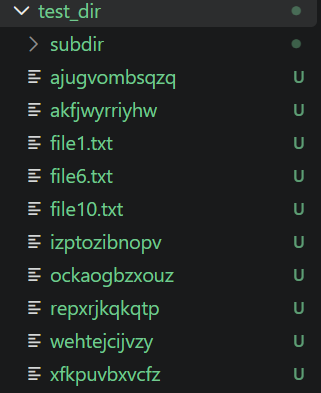

In [ ]:
;;My library of useful functions named func.asm

;Function printing of string
;input rsi - place of memory of begin string
print_str:
    push rax
    push rdi
    push rdx
    push rcx
    mov rax, rsi
    call len_str
    mov rdx, rax
    mov rax, 1
    mov rdi, 1
    syscall
    pop rcx
    pop rdx
    pop rdi
    pop rax
    ret

;The function makes new line
new_line:
   push rax
   push rdi
   push rsi
   push rdx
   push rcx
   mov rax, 0xA
   push rax
   mov rdi, 1
   mov rsi, rsp
   mov rdx, 1
   mov rax, 1
   syscall
   pop rax
   pop rcx
   pop rdx
   pop rsi
   pop rdi
   pop rax
   ret


;The function finds the length of a string
;input rax - place of memory of begin string
;output rax - length of the string
len_str:
  push rdx
  mov rdx, rax
  .iter:
      cmp byte [rax], 0
      je .next
      inc rax
      jmp .iter
  .next:
     sub rax, rdx
     pop rdx
     ret


;Function converting the string to the number
;input rsi - place of memory of begin string
;output rax - the number from the string
str_number:
    push rcx
    push rbx

    xor rax,rax
    xor rcx,rcx
.loop:
    xor     rbx, rbx
    mov     bl, byte [rsi+rcx]
    cmp     bl, 48
    jl      .finished
    cmp     bl, 57
    jg      .finished

    sub     bl, 48
    add     rax, rbx
    mov     rbx, 10
    mul     rbx
    inc     rcx
    jmp     .loop

.finished:
    cmp     rcx, 0
    je      .restore
    mov     rbx, 10
    div     rbx

.restore:
    pop rbx
    pop rcx
    ret

;The function converts the nubmer to string
;input rax - number
;rsi -address of begin of string
number_str:
  push rbx
  push rcx
  push rdx
  xor rcx, rcx
  mov rbx, 10
  .loop_1:
    xor rdx, rdx
    div rbx
    add rdx, 48
    push rdx
    inc rcx
    cmp rax, 0
    jne .loop_1
  xor rdx, rdx
  .loop_2:
    pop rax
    mov byte [rsi+rdx], al
    inc rdx
    dec rcx
    cmp rcx, 0
  jne .loop_2
  mov byte [rsi+rdx], 0
  pop rdx
  pop rcx
  pop rbx
  ret

;The function copying the string
;input rsi - src
;      rdi - dest
;output rdi - null-terminator
copy_str:
    push rax
.l1:
    mov al, byte [rsi]
    mov byte [rdi], al
    cmp al, 0
    je .l2
    inc rsi
    inc rdi
    jmp .l1
.l2:
    pop rax
    ret

;The function realizates user input from the keyboard
;input: rsi - place of memory saved input string
input_keyboard:
  push rax
  push rdi
  push rdx

  mov rax, 0
  mov rdi, 0
  mov rdx, 255
  syscall

  xor rcx, rcx
  .loop:
     mov al, [rsi+rcx]
     inc rcx
     cmp rax, 0x0A
     jne .loop
  dec rcx
  mov byte [rsi+rcx], 0

  pop rdx
  pop rdi
  pop rax
  ret

;Function exit
exit:
     mov rax, 60
     mov rdi, 0
     syscall


In [2]:
import random as rd

Variant = 14
rd.seed(Variant+86554338)

Numbers_of_problems = [rd.sample(range(5),1)[0]+1, rd.sample(range(5),1)[0]+1, rd.sample(range(5),1)[0]+1]
print(Numbers_of_problems)


[2, 2, 3]
